# Election survey analysis

Three data sources (in `data/`):

| File | Content |
|---|---|
| `private_dataM.xlsx` | **Survey** (n = 200): demographics + voting channel (`evote`) + `party` |
| `public_data_registerM.xlsx` | **Population register** (n = 1543): demographics + `last_voted` (0 paper, 1 e-vote, 2 abstained) |
| `public_data_resultsM.xlsx` | **Official results** per polling station (ZIP) and for e-votes |

Questions:

* **(A)** Do survey preferences differ significantly from the official results, for e-votes and for polling-station votes?
* **(B)** Do political preferences differ by demographic attributes (age, sex, education, …)?
* **(C)** Does the choice of voting channel (online vs. in person) differ by demographic attributes?

Significance level throughout: **α = 0.05**. Where many tests are run for one question, Holm–Bonferroni correction is applied in addition to raw p-values.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.special import gammaln
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.proportion import proportion_confint

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
PARTY_COLORS = {"Red": "#d62728", "Green": "#2ca02c", "Invalid vote": "#7f7f7f"}
CHANNEL_COLORS = {"Paper": "#1f77b4", "Electronic": "#ff7f0e"}
ALPHA = 0.05

survey = pd.read_excel("data/private_dataM.xlsx")
register = pd.read_excel("data/public_data_registerM.xlsx")
results = pd.read_excel("data/public_data_resultsM.xlsx").rename(columns={"Unnamed: 0": "unit"})

print(survey.shape, register.shape, results.shape)
survey.head()

(200, 9) (1543, 7) (6, 5)


,name,sex,evote,dob,zip,education,citizenship,marital_status,party
0,"al-Hai, Maa'iz",Male,1,2003-10-07,2400,Vocational bachelors educations,Denmark,Never married,Green
1,"el-Abdallah, Najwa",Female,1,1988-12-07,2300,Short cycle higher education,Denmark,Married/separated,Red
2,"Kelley, Charles Cory",Male,0,1966-04-19,2400,Masters programmes,Denmark,Married/separated,Red
3,"Trujillo, Maribel",Female,0,1953-02-14,2300,Vocational bachelors educations,Denmark,Married/separated,Red
4,"Lefholz, Rafael",Male,0,1988-09-30,2200,Vocational bachelors educations,Denmark,Never married,Green


## 0. Data overview and preparation

In [2]:
display(results)
print("Missing values  survey:", survey.isna().sum().sum(), "| register:", register.isna().sum().sum())
for col in ["sex", "evote", "zip", "education", "marital_status", "citizenship", "party"]:
    print(f"\n{col}:\n{survey[col].value_counts().to_string()}")

,unit,Red,Green,Invalid ballots,Total
0,Polling station: ZIP 2100,27,96,4,127
1,Polling station: ZIP 2200,56,117,2,175
2,Polling station: ZIP 2300,78,89,3,170
3,Polling station: ZIP 2400,89,166,3,258
4,E-votes,110,235,6,351
5,Total,360,703,18,1081


Missing values  survey: 0 | register: 0

sex:
sex
Female    110
Male       90

evote:
evote
0    136
1     64

zip:
zip
2400    64
2300    52
2200    52
2100    32

education:
education
Vocational Education and Training (VET)    60
Primary education                          39
Vocational bachelors educations            32
Masters programmes                         27
Upper secondary education                  24
Short cycle higher education                9
Bachelors programmes                        4
Not stated                                  3
PhD programmes                              2

marital_status:
marital_status
Never married        82
Married/separated    81
Divorced             30
Widowed               7

citizenship:
citizenship
Denmark      186
Thailand       3
Poland         3
Sweden         3
Argentina      1
Bulgaria       1
Vietnam        1
Syria          1
Ukraine        1

party:
party
Green           127
Red              71
Invalid vote      2


**Derived variables**

* **Age** – the election date is not given. The youngest person in the register was born on 2005‑02‑22 and must have been eligible (18+), so the election was held after Feb 2023; we use a reference date of 2023‑06‑01. An error of a few months does not affect any of the tests.
* **Age group** – `18–29, 30–44, 45–59, 60–74, 75+`.
* **Education level** – the 9 categories are sparse (e.g. 2 PhDs, 4 Bachelors), so for contingency-table tests they are grouped into the ISCED-like levels *Basic* (primary, upper secondary), *Vocational / short* (VET, short cycle) and *Higher* (vocational bachelor, bachelor, master, PhD). *Not stated* (n=3) is dropped from education tests.
* **Citizenship** – 186/200 are Danish, so it is reduced to *Danish* vs *Non‑Danish*.
* **Marital status** – *Widowed* (n=7) is small; tests use Fisher–Freeman–Halton (Monte‑Carlo permutation) where expected counts are low.

In [3]:
REF_DATE = pd.Timestamp("2023-06-01")
AGE_BINS = [17, 29, 44, 59, 74, 120]
AGE_LABELS = ["18-29", "30-44", "45-59", "60-74", "75+"]

EDU_ORDER = [
    "Primary education", "Upper secondary education",
    "Vocational Education and Training (VET)", "Short cycle higher education",
    "Vocational bachelors educations", "Bachelors programmes",
    "Masters programmes", "PhD programmes",
]
EDU_GROUP = {
    "Primary education": "Basic", "Upper secondary education": "Basic",
    "Vocational Education and Training (VET)": "Vocational/short",
    "Short cycle higher education": "Vocational/short",
    "Vocational bachelors educations": "Higher", "Bachelors programmes": "Higher",
    "Masters programmes": "Higher", "PhD programmes": "Higher",
}
EDU_GROUP_ORDER = ["Basic", "Vocational/short", "Higher"]
MARITAL_ORDER = ["Never married", "Married/separated", "Divorced", "Widowed"]


def add_derived(df):
    df = df.copy()
    df["age"] = ((REF_DATE - df["dob"]).dt.days / 365.25).astype(int)
    df["age_group"] = pd.cut(df["age"], AGE_BINS, labels=AGE_LABELS)
    df["citizen"] = np.where(df["citizenship"] == "Denmark", "Danish", "Non-Danish")
    df["zip"] = df["zip"].astype(str)
    return df


survey = add_derived(survey)
survey["edu_group"] = pd.Categorical(survey["education"].map(EDU_GROUP), EDU_GROUP_ORDER)
survey["edu_rank"] = survey["education"].map({e: i for i, e in enumerate(EDU_ORDER)})  # NaN for "Not stated"
survey["channel"] = survey["evote"].map({0: "Paper", 1: "Electronic"})

register = add_derived(register)
register["channel"] = register["last_voted"].map({0: "Paper", 1: "Electronic", 2: "Abstained"})

survey[["age", "age_group", "edu_group", "citizen", "channel"]].describe(include="all")

,age,age_group,edu_group,citizen,channel
count,200.000000,200,197,200,200
unique,NaN,5,3,2,2
top,NaN,45-59,Vocational/short,Danish,Paper
freq,NaN,58,69,186,136
mean,46.640000,NaN,NaN,NaN,NaN
std,17.502632,NaN,NaN,NaN,NaN
min,18.000000,NaN,NaN,NaN,NaN
25%,32.750000,NaN,NaN,NaN,NaN
50%,45.500000,NaN,NaN,NaN,NaN
75%,59.000000,NaN,NaN,NaN,NaN


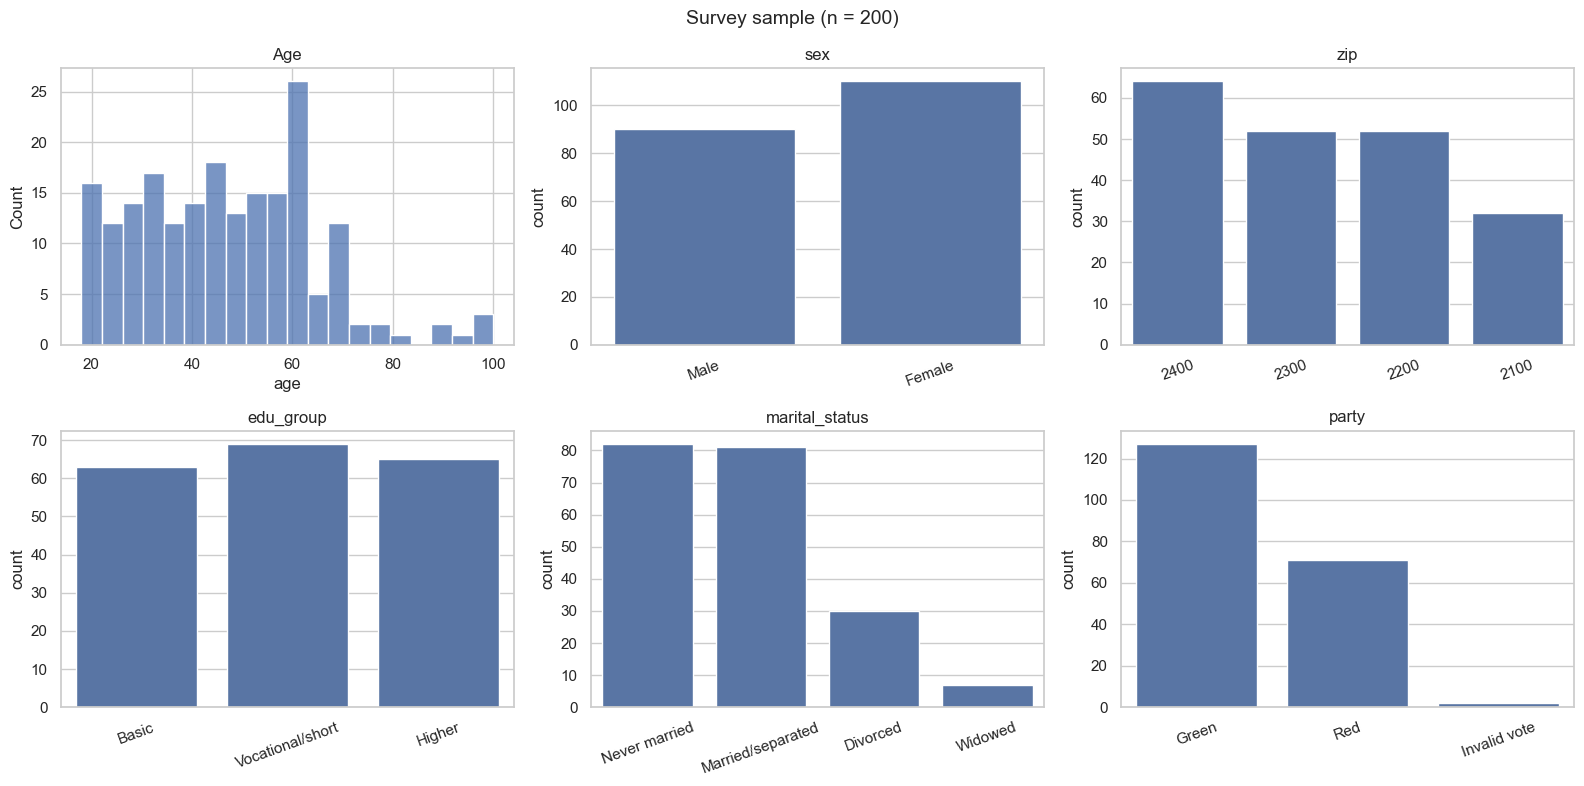

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
sns.histplot(survey, x="age", bins=20, ax=axes[0, 0], color="#4c72b0"); axes[0, 0].set_title("Age")
for ax, col, order in [
    (axes[0, 1], "sex", None), (axes[0, 2], "zip", None),
    (axes[1, 0], "edu_group", EDU_GROUP_ORDER), (axes[1, 1], "marital_status", MARITAL_ORDER),
    (axes[1, 2], "party", ["Green", "Red", "Invalid vote"]),
]:
    sns.countplot(survey, x=col, order=order, ax=ax, color="#4c72b0")
    ax.set_title(col); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=20)
fig.suptitle("Survey sample (n = 200)", fontsize=14)
plt.tight_layout(); plt.show()

### Representativeness check (survey vs. population register)

Before comparing preferences it is useful to know whether the survey sample looks like the voting population. We compare the survey with the register restricted to people who actually voted (`last_voted` ∈ {0,1}) using χ² goodness-of-fit tests (categorical) and a Kolmogorov–Smirnov test (age).

In [5]:
voters = register[register["last_voted"].isin([0, 1])]
rows = []
for col in ["sex", "zip", "marital_status", "citizen", "channel"]:
    pop = voters[col].value_counts(normalize=True)
    obs = survey[col].value_counts().reindex(pop.index, fill_value=0)
    exp = pop * obs.sum()
    chi2, p = stats.chisquare(obs, exp)
    rows.append({"variable": col, "test": "chi2 GOF", "statistic": chi2, "df": len(pop) - 1, "p": p,
                 "min expected": exp.min()})
ks = stats.ks_2samp(survey["age"], voters["age"])
rows.append({"variable": "age", "test": "KS 2-sample", "statistic": ks.statistic, "df": np.nan, "p": ks.pvalue,
             "min expected": np.nan})
repr_tbl = pd.DataFrame(rows)
repr_tbl["significant"] = repr_tbl["p"] < ALPHA
repr_tbl.round(4)

,variable,test,statistic,df,p,min expected,significant
0,sex,chi2 GOF,0.2902,1.0,0.5901,93.8020,False
1,zip,chi2 GOF,1.0435,3.0,0.7907,35.8927,False
2,marital_status,chi2 GOF,5.4339,3.0,0.1426,8.8807,False
3,citizen,chi2 GOF,0.7978,1.0,0.3718,17.5763,False
4,channel,chi2 GOF,0.0201,1.0,0.8871,64.9399,False
5,age,KS 2-sample,0.0406,NaN,0.9311,NaN,False


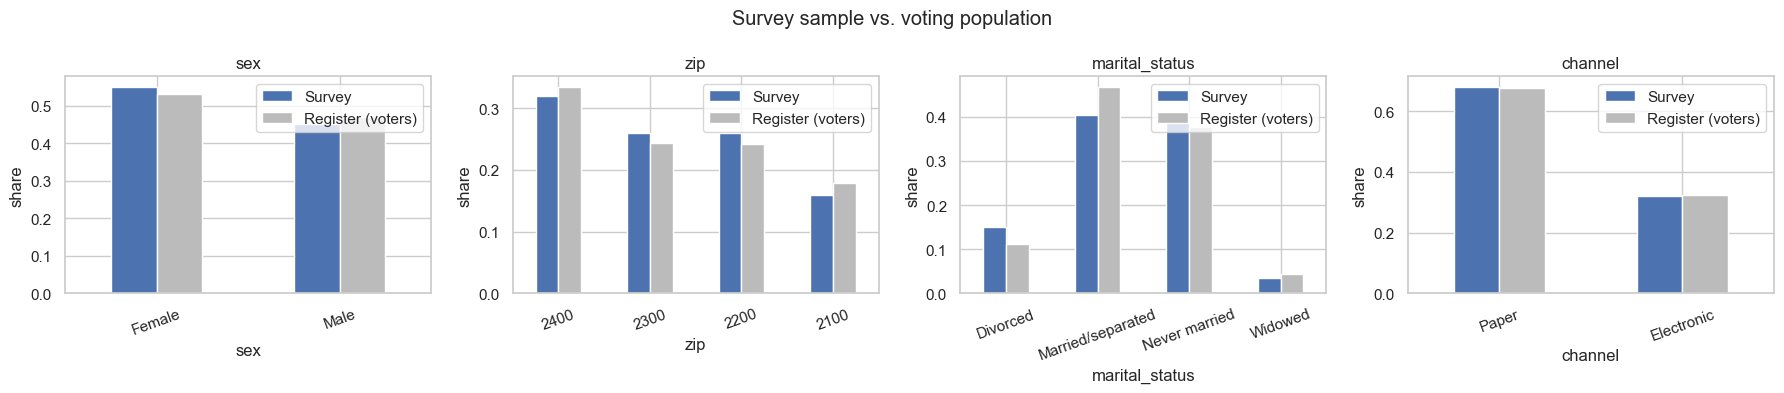

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, ["sex", "zip", "marital_status", "channel"]):
    comp = pd.DataFrame({
        "Survey": survey[col].value_counts(normalize=True),
        "Register (voters)": voters[col].value_counts(normalize=True),
    })
    comp.plot.bar(ax=ax, rot=20, color=["#4c72b0", "#bbbbbb"])
    ax.set_title(col); ax.set_ylabel("share")
plt.suptitle("Survey sample vs. voting population"); plt.tight_layout(); plt.show()

---
## (A) Survey preferences vs. official election results

**Method.** The official results are the *population* outcome, the survey is a *sample*. For each channel we test

* H₀: the survey respondents' vote distribution equals the official distribution for that channel.

Tests:
1. **χ² goodness-of-fit** on Red / Green / Invalid. Expected counts for *Invalid* are very small (≈1–3), which violates the χ² rule of thumb, so we also
2. use an **exact multinomial test** (Monte‑Carlo, 200 000 simulations) on the same 3 categories, and
3. an **exact binomial test** on the Red share among valid votes (Red vs. Green), the substantively interesting quantity.

Polling-station votes are tested both pooled and per ZIP (each ZIP has its own polling station in the results table).

In [7]:
res = results.set_index("unit")[["Red", "Green", "Invalid ballots"]]
res.columns = ["Red", "Green", "Invalid vote"]
res.loc["Polling stations (all)"] = res.filter(like="Polling station", axis=0).sum()
CATS = ["Red", "Green", "Invalid vote"]

rng = np.random.default_rng(42)


def multinomial_mc_p(obs, probs, n_sim=200_000):
    # P(multinomial log-likelihood <= observed) under H0 – exact-style MC test
    obs = np.asarray(obs); probs = np.asarray(probs, float)
    def loglik(x):
        return (x * np.log(np.where(probs > 0, probs, 1))).sum(axis=-1) - gammaln(x + 1).sum(axis=-1)
    sims = rng.multinomial(obs.sum(), probs, size=n_sim)
    return (np.sum(loglik(sims) <= loglik(obs) + 1e-9) + 1) / (n_sim + 1)


def compare(sub, official_row, label):
    obs = sub["party"].value_counts().reindex(CATS, fill_value=0)
    p_off = res.loc[official_row, CATS] / res.loc[official_row, CATS].sum()
    exp = p_off * obs.sum()
    chi2, p_chi = stats.chisquare(obs, exp)
    p_mn = multinomial_mc_p(obs.values, p_off.values)
    valid = obs["Red"] + obs["Green"]
    red_off = res.loc[official_row, "Red"] / (res.loc[official_row, "Red"] + res.loc[official_row, "Green"])
    bt = stats.binomtest(int(obs["Red"]), int(valid), red_off)
    ci = bt.proportion_ci(method="wilson")
    return {
        "group": label, "n survey": int(obs.sum()),
        "survey Red/Green/Inv": f"{obs['Red']}/{obs['Green']}/{obs['Invalid vote']}",
        "official Red share (valid)": red_off, "survey Red share (valid)": obs["Red"] / valid,
        "95% CI low": ci.low, "95% CI high": ci.high,
        "chi2": chi2, "p chi2": p_chi, "p exact multinomial": p_mn, "p binomial (Red share)": bt.pvalue,
    }


rows = [
    compare(survey[survey.evote == 1], "E-votes", "Electronic"),
    compare(survey[survey.evote == 0], "Polling stations (all)", "Paper (all ZIPs)"),
]
for z in ["2100", "2200", "2300", "2400"]:
    rows.append(compare(survey[(survey.evote == 0) & (survey.zip == z)], f"Polling station: ZIP {z}", f"Paper ZIP {z}"))
# overall, for completeness
res.loc["All votes"] = res.loc[["E-votes", "Polling stations (all)"]].sum()
rows.append(compare(survey, "All votes", "All votes"))

A = pd.DataFrame(rows).set_index("group")
A["p binomial Holm"] = multipletests(A["p binomial (Red share)"], method="holm")[1]
A.round(4)

,n survey,survey Red/Green/Inv,official Red share (valid),survey Red share (valid),95% CI low,95% CI high,chi2,p chi2,p exact multinomial,p binomial (Red share),p binomial Holm
group,,,,,,,,,,,
Electronic,64,18/46/0,0.3188,0.2812,0.1859,0.4013,1.5367,0.4638,0.6800,0.5926,1.0000
Paper (all ZIPs),136,53/81/2,0.3482,0.3955,0.3168,0.4801,1.3504,0.5091,0.5146,0.2764,1.0000
Paper ZIP 2100,19,3/16/0,0.2195,0.1579,0.0552,0.3757,1.0526,0.5908,0.8804,0.7814,1.0000
Paper ZIP 2200,40,12/27/1,0.3237,0.3077,0.1857,0.4642,0.6971,0.7057,0.5183,1.0000,1.0000
Paper ZIP 2300,33,20/12/1,0.4671,0.6250,0.4525,0.7707,3.4702,0.1764,0.1104,0.0785,0.5498
Paper ZIP 2400,44,18/26/0,0.3490,0.4091,0.2769,0.5559,1.2247,0.5421,0.6596,0.4304,1.0000
All votes,200,71/127/2,0.3387,0.3586,0.2951,0.4275,0.8936,0.6397,0.7139,0.5489,1.0000


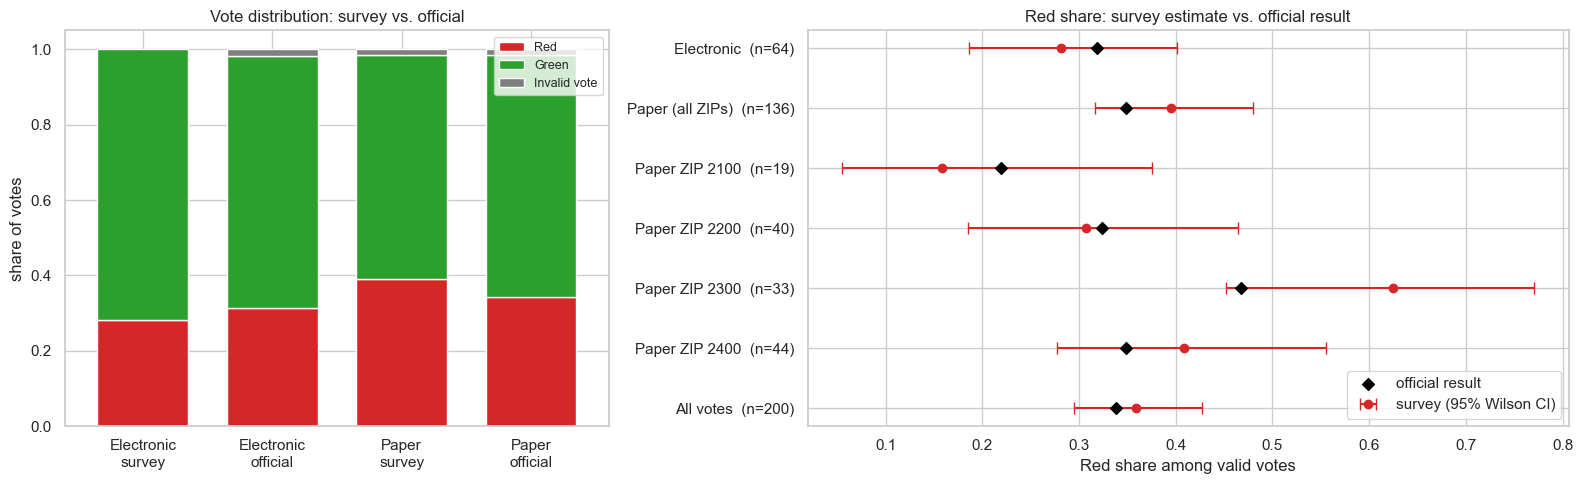

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={"width_ratios": [1, 1.4]})

# left: stacked shares survey vs official, per channel
plot_rows = []
for label, mask, off in [("Electronic", survey.evote == 1, "E-votes"),
                         ("Paper", survey.evote == 0, "Polling stations (all)")]:
    s = survey.loc[mask, "party"].value_counts(normalize=True).reindex(CATS, fill_value=0)
    o = res.loc[off, CATS] / res.loc[off, CATS].sum()
    plot_rows += [pd.Series(s, name=f"{label}\nsurvey"), pd.Series(o, name=f"{label}\nofficial")]
shares = pd.DataFrame(plot_rows)
shares.plot.bar(stacked=True, ax=axes[0], color=[PARTY_COLORS[c] for c in CATS], rot=0, width=0.7)
axes[0].set_ylabel("share of votes"); axes[0].set_title("Vote distribution: survey vs. official")
axes[0].legend(loc="upper right", bbox_to_anchor=(1.0, 1.0), fontsize=9)

# right: Red share among valid votes with 95% CI vs official
ax = axes[1]
y = np.arange(len(A))
ax.errorbar(A["survey Red share (valid)"], y,
            xerr=[A["survey Red share (valid)"] - A["95% CI low"], A["95% CI high"] - A["survey Red share (valid)"]],
            fmt="o", color="#d62728", capsize=4, label="survey (95% Wilson CI)")
ax.scatter(A["official Red share (valid)"], y, marker="D", color="black", zorder=3, label="official result")
ax.set_yticks(y); ax.set_yticklabels([f"{g}  (n={n})" for g, n in zip(A.index, A["n survey"])])
ax.invert_yaxis(); ax.set_xlabel("Red share among valid votes"); ax.legend(loc="lower right")
ax.set_title("Red share: survey estimate vs. official result")
plt.tight_layout(); plt.show()

**Interpretation (A).** Read the table above: a p-value < 0.05 means the survey distribution for that channel differs significantly from the official result. Note the per‑ZIP paper samples are small (n≈19–44), so those tests have low power; the Holm-adjusted column controls the family-wise error over the 7 comparisons. The CI plot shows directly whether the official Red share lies inside the survey's 95 % confidence interval.

In [9]:
def verdict(p):
    return "SIGNIFICANT difference" if p < ALPHA else "no significant difference"

for g in ["Electronic", "Paper (all ZIPs)", "All votes"]:
    r = A.loc[g]
    print(f"{g:18s}: survey Red {r['survey Red share (valid)']:.1%} vs official {r['official Red share (valid)']:.1%} | "
          f"chi2 p={r['p chi2']:.4f}, exact multinomial p={r['p exact multinomial']:.4f}, "
          f"binomial p={r['p binomial (Red share)']:.4f} -> {verdict(r['p exact multinomial'])}")

Electronic        : survey Red 28.1% vs official 31.9% | chi2 p=0.4638, exact multinomial p=0.6800, binomial p=0.5926 -> no significant difference
Paper (all ZIPs)  : survey Red 39.6% vs official 34.8% | chi2 p=0.5091, exact multinomial p=0.5146, binomial p=0.2764 -> no significant difference
All votes         : survey Red 35.9% vs official 33.9% | chi2 p=0.6397, exact multinomial p=0.7139, binomial p=0.5489 -> no significant difference


---
## (B) Political preference vs. demographic attributes

**Outcome:** party choice among valid votes (Red vs. Green; the 2 invalid votes are excluded).

**Method.**
* *Categorical attributes* (sex, age group, education group, marital status, ZIP, citizenship, voting channel): **χ² test of independence** with **Cramér's V** as effect size. When >20 % of expected counts are < 5, the **Fisher exact test** (2×2) or a **Monte‑Carlo permutation χ² test** (r×2) is used instead.
* *Continuous / ordinal attributes* (age, education rank): **Mann–Whitney U** test between Red and Green voters.
* **Multivariable logistic regression** (Red = 1) to see which attributes remain associated with party choice when controlling for the others.
* Holm correction across the attribute family.

In [10]:
def cramers_v(ct):
    chi2 = stats.chi2_contingency(ct, correction=False)[0]
    n = ct.values.sum(); r, k = ct.shape
    return np.sqrt(chi2 / (n * (min(r, k) - 1)))


def perm_chi2_p(x, y, n_perm=20_000, seed=0):
    r = np.random.default_rng(seed)
    obs = stats.chi2_contingency(pd.crosstab(x, y), correction=False)[0]
    y = np.asarray(y); x = np.asarray(x)
    cnt = 0
    for _ in range(n_perm):
        cnt += stats.chi2_contingency(pd.crosstab(x, r.permutation(y)), correction=False)[0] >= obs - 1e-12
    return (cnt + 1) / (n_perm + 1)


def assoc_table(df, outcome, attrs):
    rows = []
    for a in attrs:
        d = df[[a, outcome]].dropna()
        ct = pd.crosstab(d[a], d[outcome])
        ct = ct.loc[ct.sum(axis=1) > 0]
        chi2, p, dof, exp = stats.chi2_contingency(ct, correction=False)
        small = (exp < 5).mean()
        if small > 0.2:
            if ct.shape == (2, 2):
                p_used, test = stats.fisher_exact(ct)[1], "Fisher exact"
            else:
                p_used, test = perm_chi2_p(d[a], d[outcome]), "permutation chi2"
        else:
            p_used, test = p, "chi2"
        rows.append({"attribute": a, "levels": ct.shape[0], "n": int(ct.values.sum()), "chi2": chi2, "df": dof,
                     "% exp<5": small * 100, "test used": test, "p": p_used, "Cramer's V": cramers_v(ct)})
    out = pd.DataFrame(rows).set_index("attribute")
    out["p Holm"] = multipletests(out["p"], method="holm")[1]
    out["significant (Holm)"] = out["p Holm"] < ALPHA
    return out


valid = survey[survey["party"].isin(["Red", "Green"])].copy()
valid["red"] = (valid["party"] == "Red").astype(int)
CAT_ATTRS = ["sex", "age_group", "edu_group", "marital_status", "zip", "citizen", "channel"]

B_cat = assoc_table(valid, "party", CAT_ATTRS)
B_cat.round(4)

,levels,n,chi2,df,% exp<5,test used,p,Cramer's V,p Holm,significant (Holm)
attribute,,,,,,,,,,
sex,2,198,1.3595,1,0.0,chi2,0.2436,0.0829,0.4604,False
age_group,5,198,31.5086,4,10.0,chi2,0.0000,0.3989,0.0000,True
edu_group,3,195,35.2442,2,0.0,chi2,0.0000,0.4251,0.0000,True
marital_status,4,198,6.6417,3,25.0,permutation chi2,0.0813,0.1832,0.3252,False
zip,4,198,16.4612,3,0.0,chi2,0.0009,0.2883,0.0046,True
citizen,2,198,1.9573,1,25.0,Fisher exact,0.2302,0.0994,0.4604,False
channel,2,198,2.4591,1,0.0,chi2,0.1168,0.1114,0.3505,False


In [11]:
rows = []
for var in ["age", "edu_rank"]:
    d = valid.dropna(subset=[var])
    red, green = d.loc[d.party == "Red", var], d.loc[d.party == "Green", var]
    u = stats.mannwhitneyu(red, green, alternative="two-sided")
    rows.append({"variable": var, "median Red": red.median(), "median Green": green.median(),
                 "mean Red": red.mean(), "mean Green": green.mean(), "U": u.statistic, "p": u.pvalue,
                 "rank-biserial r": 1 - 2 * u.statistic / (len(red) * len(green))})
B_num = pd.DataFrame(rows).set_index("variable")
B_num.round(4)

,median Red,median Green,mean Red,mean Green,U,p,rank-biserial r
variable,,,,,,,
age,55.0,39.0,55.3803,41.8346,6564.0,0.0,-0.4559
edu_rank,4.0,2.0,3.4930,1.9677,6350.0,0.0,-0.4425


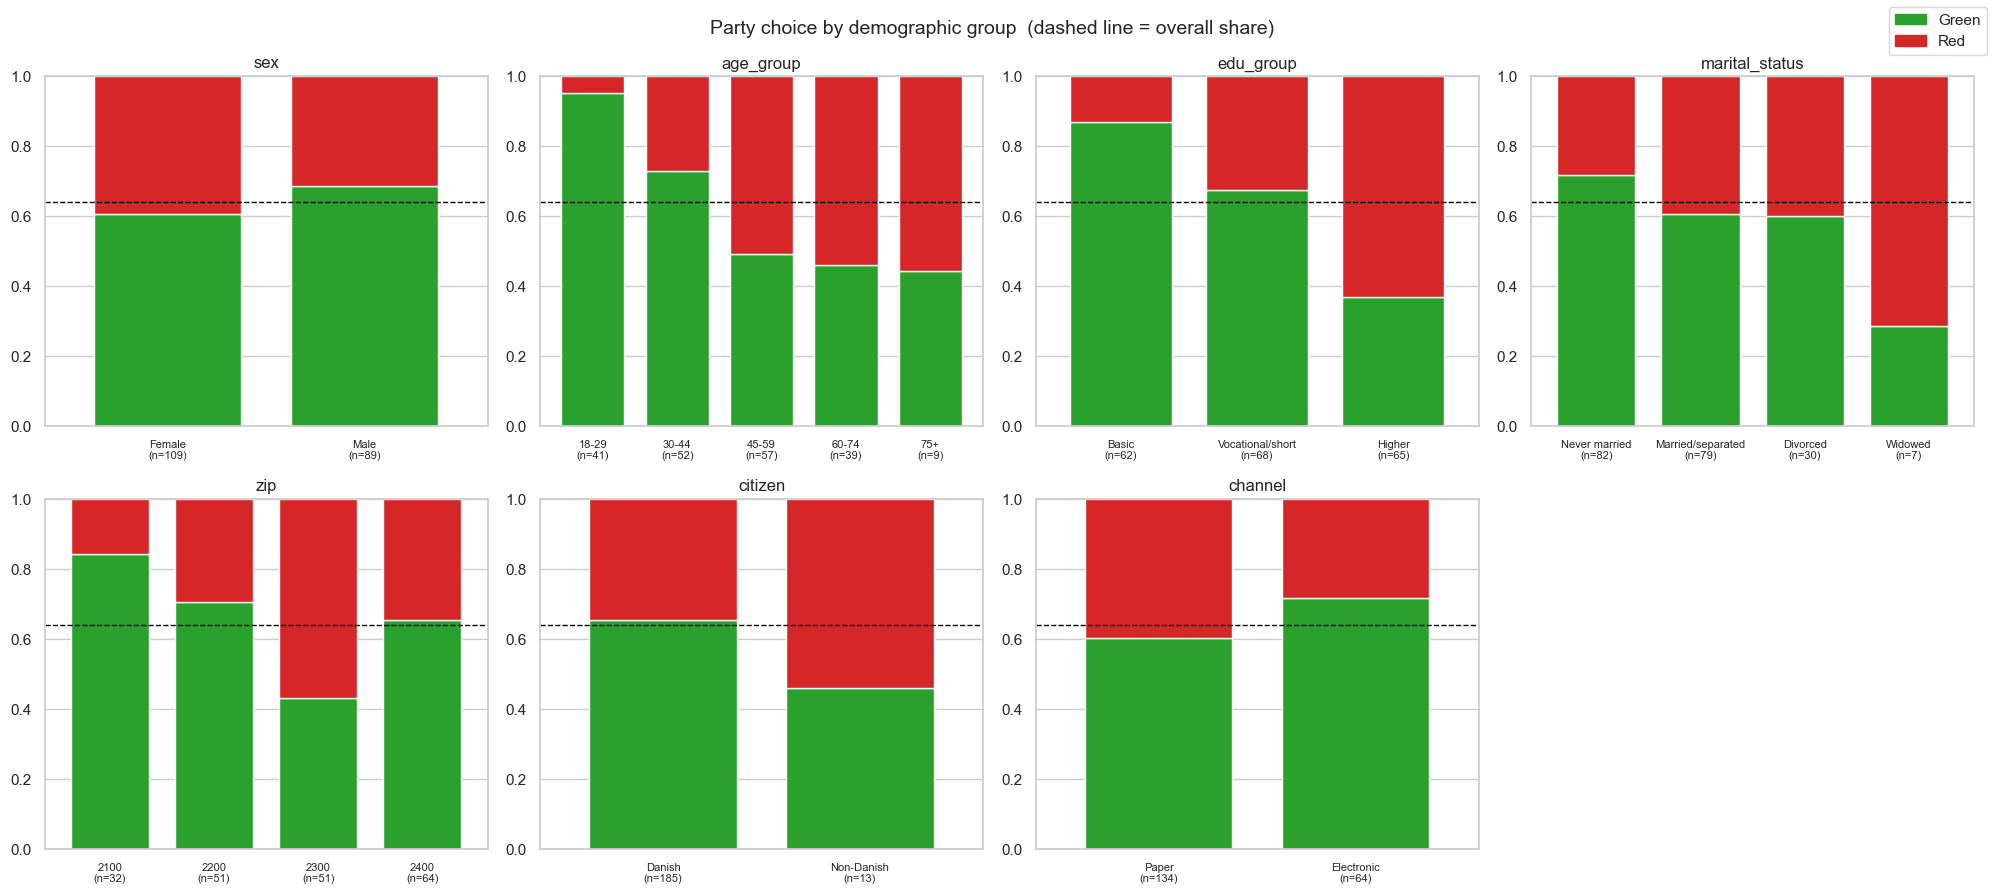

In [12]:
def plot_shares(df, outcome, attrs, orders, colors, title):
    n = len(attrs)
    fig, axes = plt.subplots(2, (n + 1) // 2, figsize=(5 * ((n + 1) // 2), 9))
    for ax, a in zip(axes.flat, attrs):
        ct = pd.crosstab(df[a], df[outcome], normalize="index")
        ct = ct.reindex(orders.get(a, ct.index)).dropna(how="all")
        ct = ct[[c for c in colors if c in ct.columns]]
        counts = df[a].value_counts()
        ct.plot.bar(stacked=True, ax=ax, color=[colors[c] for c in ct.columns], legend=False, width=0.75)
        ax.set_xticklabels([f"{i}\n(n={counts.get(i, 0)})" for i in ct.index], rotation=0, fontsize=8)
        overall = df[outcome].value_counts(normalize=True)[list(colors)[1]]
        ax.axhline(1 - overall, color="black", ls="--", lw=1)
        ax.set_title(a); ax.set_xlabel(""); ax.set_ylim(0, 1)
    for ax in list(axes.flat)[n:]:
        ax.axis("off")
    handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in colors.values()]
    fig.legend(handles, colors.keys(), loc="upper right")
    fig.suptitle(title + "  (dashed line = overall share)", fontsize=14)
    plt.tight_layout(); plt.show()


ORDERS = {"age_group": AGE_LABELS, "edu_group": EDU_GROUP_ORDER, "marital_status": MARITAL_ORDER,
          "channel": ["Paper", "Electronic"]}
plot_shares(valid, "party", CAT_ATTRS, ORDERS, {"Green": PARTY_COLORS["Green"], "Red": PARTY_COLORS["Red"]},
            "Party choice by demographic group")

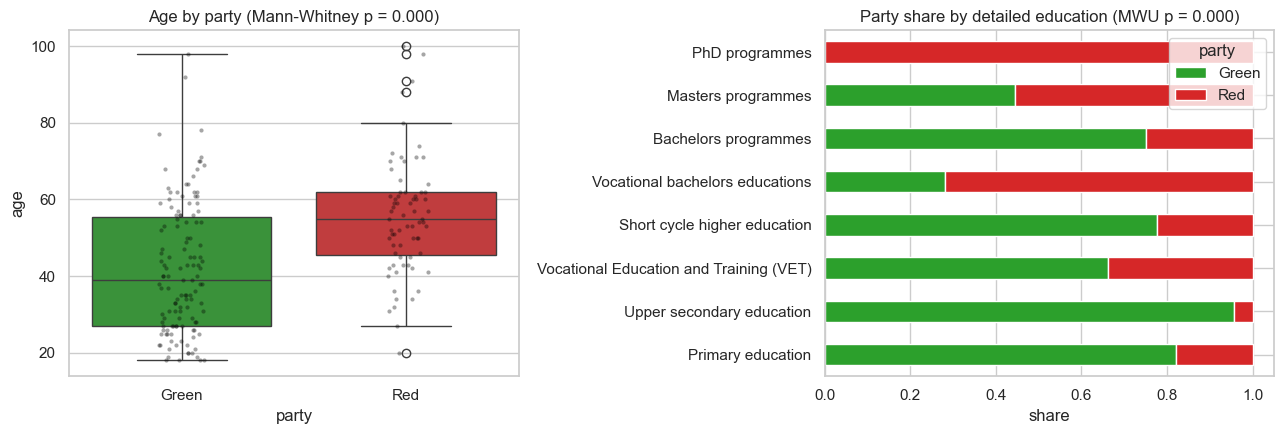

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.boxplot(valid, x="party", y="age", hue="party", palette=PARTY_COLORS, ax=axes[0], legend=False)
sns.stripplot(valid, x="party", y="age", color="black", alpha=0.35, size=3, ax=axes[0])
axes[0].set_title(f"Age by party (Mann-Whitney p = {B_num.loc['age', 'p']:.3f})")

edu_ct = pd.crosstab(valid["education"], valid["party"], normalize="index").reindex(EDU_ORDER).dropna()
edu_ct[["Green", "Red"]].plot.barh(stacked=True, ax=axes[1], color=[PARTY_COLORS["Green"], PARTY_COLORS["Red"]])
axes[1].set_title(f"Party share by detailed education (MWU p = {B_num.loc['edu_rank', 'p']:.3f})")
axes[1].set_xlabel("share"); axes[1].set_ylabel("")
plt.tight_layout(); plt.show()

### Multivariable logistic regression (Red = 1)

Controls for all attributes simultaneously (age as continuous, per 10 years). Reference categories: Female, Basic education, Never married, ZIP 2100, Danish, Paper. Odds ratios > 1 mean higher odds of voting Red.

n = 195, pseudo-R² (McFadden) = 0.349, LR test vs null: chi2 = 89.30, p = 0.0000


,OR,CI low,CI high,p
"C(sex, Treatment('Female'))[T.Male]",0.3612,0.1553,0.8398,0.0180
"C(edu_group, Treatment('Basic'))[T.Vocational/short]",3.2467,1.1500,9.1663,0.0262
"C(edu_group, Treatment('Basic'))[T.Higher]",21.5815,6.7566,68.9346,0.0000
"C(marital_status, Treatment('Never married'))[T.Divorced]",0.5392,0.1590,1.8291,0.3217
"C(marital_status, Treatment('Never married'))[T.Married/separated]",0.8608,0.3255,2.2765,0.7626
"C(marital_status, Treatment('Never married'))[T.Widowed]",0.4983,0.0443,5.6004,0.5725
C(zip)[T.2200],2.9074,0.6433,13.1390,0.1655
C(zip)[T.2300],9.8608,2.1507,45.2109,0.0032
C(zip)[T.2400],3.0501,0.7248,12.8361,0.1283
C(citizen)[T.Non-Danish],2.2971,0.4972,10.6126,0.2868


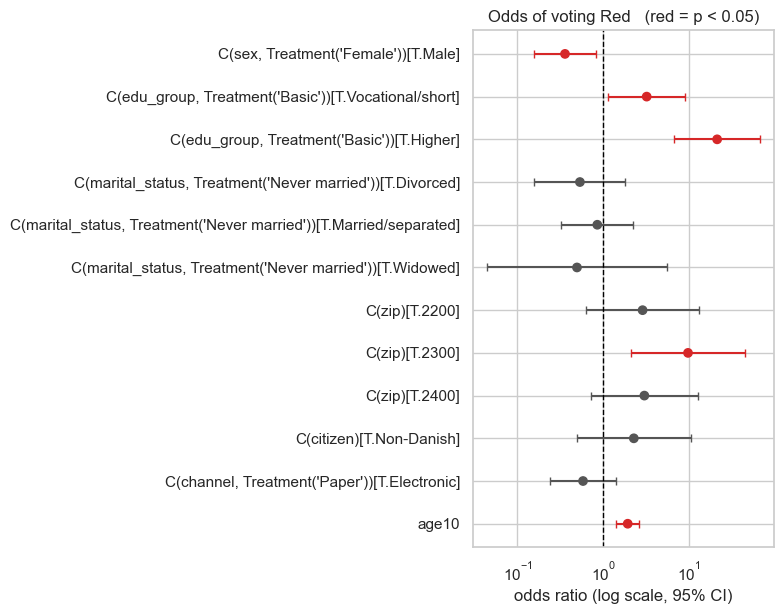

In [17]:
def fit_logit(formula, data):
    m = smf.logit(formula, data=data).fit(disp=False)
    ci = np.exp(m.conf_int())
    tbl = pd.DataFrame({"OR": np.exp(m.params), "CI low": ci[0], "CI high": ci[1], "p": m.pvalues}).drop("Intercept")
    lr_p = m.llr_pvalue
    print(f"n = {int(m.nobs)}, pseudo-R² (McFadden) = {m.prsquared:.3f}, LR test vs null: chi2 = {m.llr:.2f}, p = {lr_p:.4f}")
    return m, tbl


def forest(tbl, title):
    t = tbl.iloc[::-1]
    fig, ax = plt.subplots(figsize=(8, 0.4 * len(t) + 1.5))
    col = np.where(t["p"] < ALPHA, "#d62728", "#555555")
    y = np.arange(len(t))
    for c in np.unique(col):  # errorbar takes one ecolor per call
        m = col == c
        ax.errorbar(t["OR"][m], y[m], xerr=[(t["OR"] - t["CI low"])[m], (t["CI high"] - t["OR"])[m]],
                    fmt="none", ecolor=c, capsize=3)
    ax.scatter(t["OR"], range(len(t)), color=col, zorder=3)
    ax.axvline(1, color="black", ls="--", lw=1); ax.set_xscale("log")
    ax.set_yticks(range(len(t))); ax.set_yticklabels(t.index)
    ax.set_xlabel("odds ratio (log scale, 95% CI)"); ax.set_title(title + "   (red = p < 0.05)")
    plt.tight_layout(); plt.show()


lr_data = valid.dropna(subset=["edu_group"]).copy()
lr_data["age10"] = lr_data["age"] / 10
FORMULA_RHS = ("age10 + C(sex, Treatment('Female')) + C(edu_group, Treatment('Basic')) "
               "+ C(marital_status, Treatment('Never married')) + C(zip) + C(citizen)")
mB, B_logit = fit_logit("red ~ " + FORMULA_RHS + " + C(channel, Treatment('Paper'))", lr_data)
display(B_logit.round(4))
forest(B_logit, "Odds of voting Red")

In [18]:
print("Attributes significantly associated with party choice (univariate, Holm-adjusted):")
sig = B_cat[B_cat["significant (Holm)"]]
print("  none" if sig.empty else sig[["test used", "p", "p Holm", "Cramer's V"]].round(4).to_string())
print("\nUnadjusted p < 0.05:", list(B_cat.index[B_cat["p"] < ALPHA]) + list(B_num.index[B_num["p"] < ALPHA]))
print("Significant in logistic regression:", list(B_logit.index[B_logit["p"] < ALPHA]))

Attributes significantly associated with party choice (univariate, Holm-adjusted):
          test used       p  p Holm  Cramer's V
attribute                                      
age_group      chi2  0.0000  0.0000      0.3989
edu_group      chi2  0.0000  0.0000      0.4251
zip            chi2  0.0009  0.0046      0.2883

Unadjusted p < 0.05: ['age_group', 'edu_group', 'zip', 'age', 'edu_rank']
Significant in logistic regression: ["C(sex, Treatment('Female'))[T.Male]", "C(edu_group, Treatment('Basic'))[T.Vocational/short]", "C(edu_group, Treatment('Basic'))[T.Higher]", 'C(zip)[T.2300]', 'age10']


**Interpretation (B).** The tables report, for each demographic attribute, whether Red/Green shares differ between groups. Cramér's V ≈ 0.1 is a small, ≈ 0.3 a medium and ≈ 0.5 a large association. The logistic regression shows which effects persist after adjusting for the other attributes (e.g. age and marital status are correlated, so a marital-status effect may really be an age effect).

---
## (C) Voting channel (online vs. in person) vs. demographic attributes

**Outcome:** `evote` (1 = electronic, 0 = paper). Same methods as in (B): χ² / Fisher / permutation tests with Cramér's V, Mann–Whitney for age and education rank, and a multivariable logistic regression (Electronic = 1).

As a robustness check we repeat the analysis on the **population register** (n ≈ 1081 people who voted), which has the same `last_voted` channel variable for sex, age, ZIP, marital status and citizenship – giving far more statistical power than the 200-person survey (education is only available in the survey).

In [19]:
C_ATTRS = ["sex", "age_group", "edu_group", "marital_status", "zip", "citizen"]
C_cat = assoc_table(survey, "channel", C_ATTRS)
C_cat.round(4)

,levels,n,chi2,df,% exp<5,test used,p,Cramer's V,p Holm,significant (Holm)
attribute,,,,,,,,,,
sex,2,200,0.0037,1,0.0,chi2,0.9514,0.0043,1.0000,False
age_group,5,200,19.3647,4,10.0,chi2,0.0007,0.3112,0.0040,True
edu_group,3,197,3.3865,2,0.0,chi2,0.1839,0.1311,0.7357,False
marital_status,4,200,5.7650,3,25.0,permutation chi2,0.1255,0.1698,0.6277,False
zip,4,200,3.5055,3,0.0,chi2,0.3201,0.1324,0.9602,False
citizen,2,200,0.0954,1,25.0,Fisher exact,0.7711,0.0218,1.0000,False


In [24]:
rows = []
for var in ["age", "edu_rank"]:
    d = survey.dropna(subset=[var])
    e, p_ = d.loc[d.evote == 1, var], d.loc[d.evote == 0, var]
    u = stats.mannwhitneyu(e, p_, alternative="two-sided")
    rows.append({"variable": var, "median Electronic": e.median(), "median Paper": p_.median(),
                 "mean Electronic": e.mean(), "mean Paper": p_.mean(), "U": u.statistic, "p": u.pvalue,
                 "rank-biserial r": 1 - 2 * u.statistic / (len(e) * len(p_))})
C_num = pd.DataFrame(rows).set_index("variable")
C_num.round(4)

,median Electronic,median Paper,mean Electronic,mean Paper,U,p,rank-biserial r
variable,,,,,,,
age,38.0,50.5,39.9375,49.7941,2906.5,0.0002,0.3321
edu_rank,2.0,2.0,2.8594,2.3459,4952.5,0.0574,-0.1637


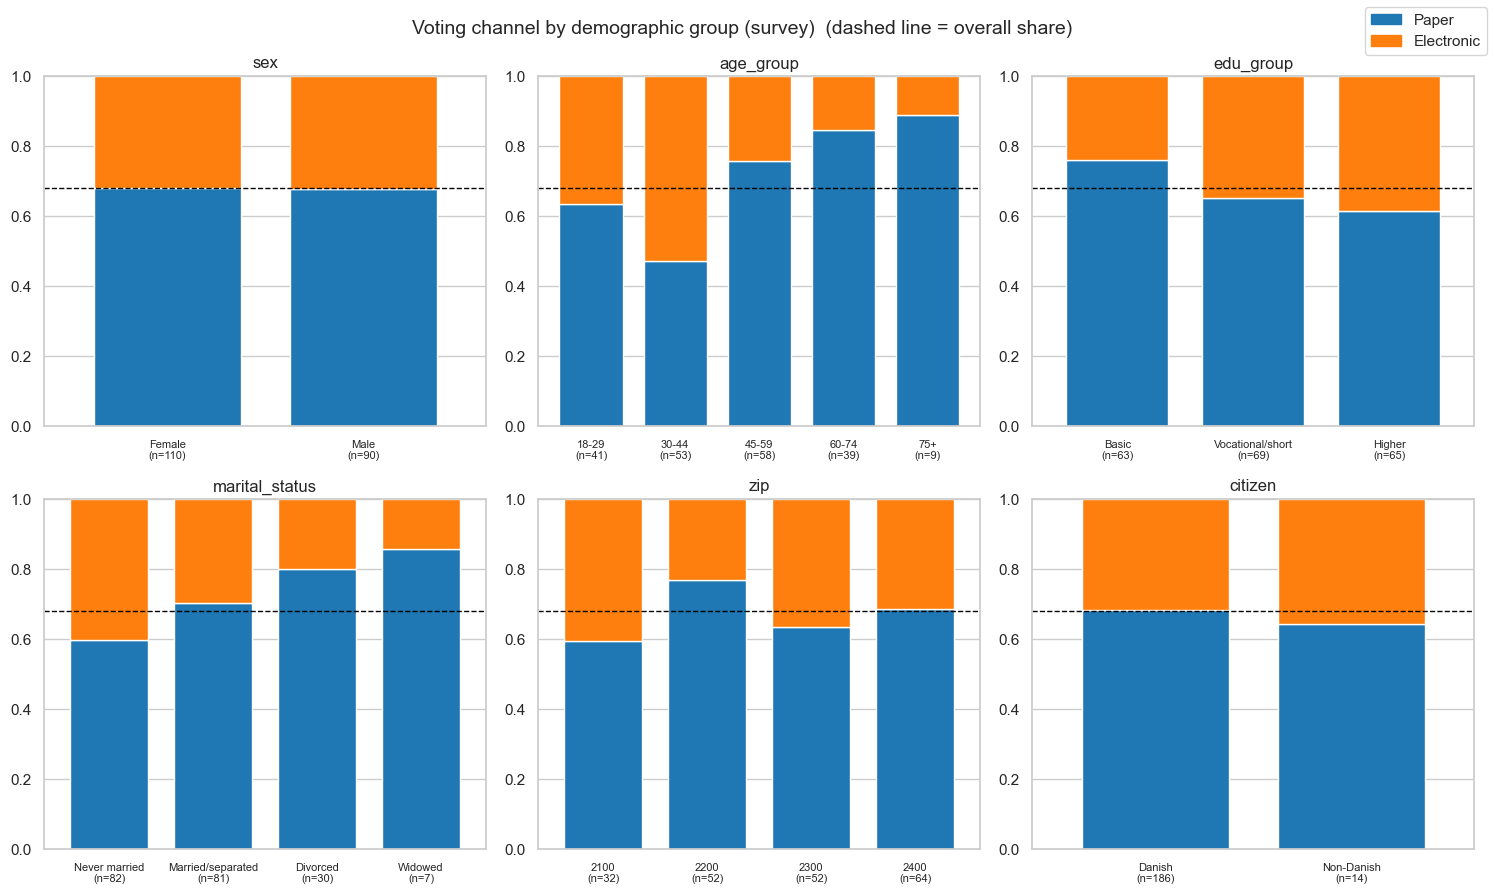

In [25]:
plot_shares(survey, "channel", C_ATTRS, ORDERS, {"Paper": CHANNEL_COLORS["Paper"], "Electronic": CHANNEL_COLORS["Electronic"]},
            "Voting channel by demographic group (survey)")

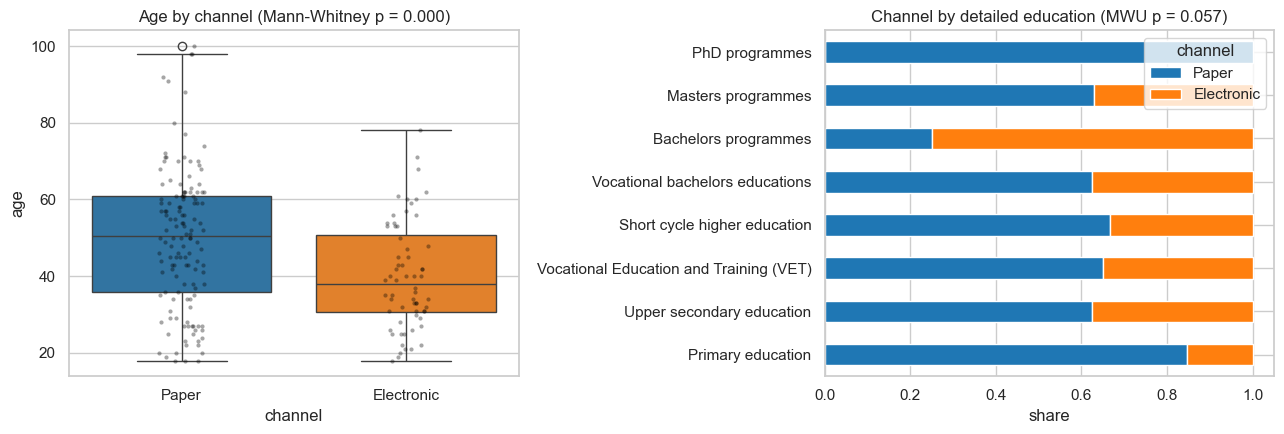

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.boxplot(survey, x="channel", y="age", hue="channel", palette=CHANNEL_COLORS, ax=axes[0], legend=False,
            order=["Paper", "Electronic"])
sns.stripplot(survey, x="channel", y="age", color="black", alpha=0.35, size=3, ax=axes[0], order=["Paper", "Electronic"])
axes[0].set_title(f"Age by channel (Mann-Whitney p = {C_num.loc['age', 'p']:.3f})")

edu_ct = pd.crosstab(survey["education"], survey["channel"], normalize="index").reindex(EDU_ORDER).dropna()
edu_ct[["Paper", "Electronic"]].plot.barh(stacked=True, ax=axes[1], color=list(CHANNEL_COLORS.values()))
axes[1].set_title(f"Channel by detailed education (MWU p = {C_num.loc['edu_rank', 'p']:.3f})")
axes[1].set_xlabel("share"); axes[1].set_ylabel("")
plt.tight_layout(); plt.show()

n = 197, pseudo-R² (McFadden) = 0.117, LR test vs null: chi2 = 29.19, p = 0.0021


,OR,CI low,CI high,p
"C(sex, Treatment('Female'))[T.Male]",1.0042,0.5099,1.9776,0.9903
"C(edu_group, Treatment('Basic'))[T.Vocational/short]",2.8044,1.1849,6.6376,0.0190
"C(edu_group, Treatment('Basic'))[T.Higher]",2.9277,1.2329,6.9523,0.0149
"C(marital_status, Treatment('Never married'))[T.Divorced]",0.6790,0.2109,2.1856,0.5163
"C(marital_status, Treatment('Never married'))[T.Married/separated]",1.0123,0.4521,2.2666,0.9762
"C(marital_status, Treatment('Never married'))[T.Widowed]",1.3850,0.1106,17.3378,0.8006
C(zip)[T.2200],0.4393,0.1549,1.2457,0.1219
C(zip)[T.2300],1.1065,0.3861,3.1710,0.8506
C(zip)[T.2400],1.1940,0.4234,3.3674,0.7375
C(citizen)[T.Non-Danish],1.2654,0.3593,4.4561,0.7140


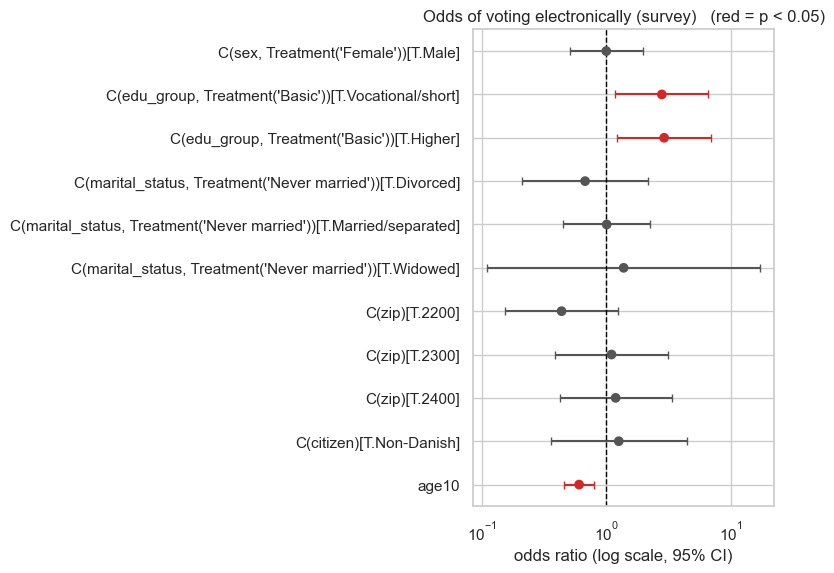

In [27]:
lr_c = survey.dropna(subset=["edu_group"]).copy()
lr_c["age10"] = lr_c["age"] / 10
mC, C_logit = fit_logit("evote ~ " + FORMULA_RHS, lr_c)
display(C_logit.round(4))
forest(C_logit, "Odds of voting electronically (survey)")

### Robustness check on the population register (all actual voters)

Register: age Electronic median 42 vs Paper 50, Mann-Whitney p = 9.35e-07


,levels,n,chi2,df,% exp<5,test used,p,Cramer's V,p Holm,significant (Holm)
attribute,,,,,,,,,,
sex,2,1081,3.0316,1,0.0,chi2,0.0817,0.0530,0.2450,False
age_group,5,1081,30.1504,4,0.0,chi2,0.0000,0.1670,0.0000,True
marital_status,4,1081,10.5546,3,0.0,chi2,0.0144,0.0988,0.0576,False
zip,4,1081,3.8994,3,0.0,chi2,0.2725,0.0601,0.5451,False
citizen,2,1081,0.0377,1,0.0,chi2,0.8460,0.0059,0.8460,False


n = 1081, pseudo-R² (McFadden) = 0.023, LR test vs null: chi2 = 31.37, p = 0.0003


,OR,CI low,CI high,p
"C(sex, Treatment('Female'))[T.Male]",1.2894,0.9948,1.6711,0.0548
"C(marital_status, Treatment('Never married'))[T.Divorced]",0.8834,0.5465,1.4280,0.6129
"C(marital_status, Treatment('Never married'))[T.Married/separated]",1.0644,0.7744,1.4631,0.7005
"C(marital_status, Treatment('Never married'))[T.Widowed]",0.7563,0.3130,1.8273,0.5349
C(zip)[T.2200],1.1191,0.7458,1.6792,0.5868
C(zip)[T.2300],1.2466,0.8334,1.8646,0.2834
C(zip)[T.2400],1.0378,0.6944,1.5511,0.8563
C(citizen)[T.Non-Danish],0.9462,0.5973,1.4988,0.8138
age10,0.8246,0.7454,0.9123,0.0002


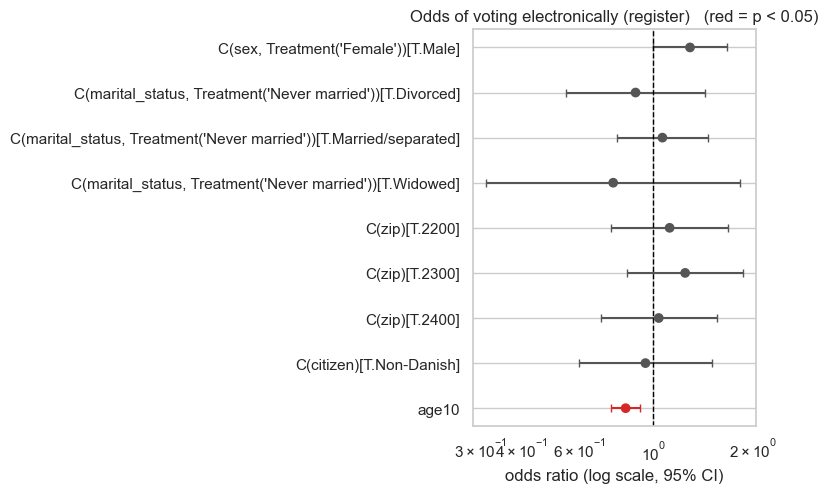

In [28]:
reg_voters = register[register["last_voted"].isin([0, 1])].copy()
reg_voters["evote"] = reg_voters["last_voted"]
C_reg = assoc_table(reg_voters, "channel", ["sex", "age_group", "marital_status", "zip", "citizen"])
u = stats.mannwhitneyu(reg_voters.loc[reg_voters.evote == 1, "age"], reg_voters.loc[reg_voters.evote == 0, "age"])
print(f"Register: age Electronic median {reg_voters.loc[reg_voters.evote == 1, 'age'].median():.0f} vs "
      f"Paper {reg_voters.loc[reg_voters.evote == 0, 'age'].median():.0f}, Mann-Whitney p = {u.pvalue:.2e}")
display(C_reg.round(4))

reg_voters["age10"] = reg_voters["age"] / 10
mR, R_logit = fit_logit("evote ~ age10 + C(sex, Treatment('Female')) + C(marital_status, Treatment('Never married')) "
                        "+ C(zip) + C(citizen)", reg_voters)
display(R_logit.round(4))
forest(R_logit, "Odds of voting electronically (register)")

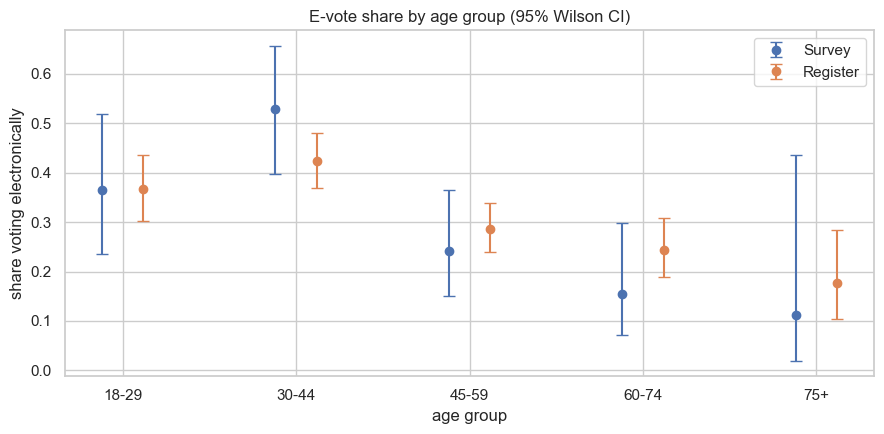

In [29]:
# e-vote share by age group: survey vs register, with 95% CIs
fig, ax = plt.subplots(figsize=(9, 4.5))
for df, label, off in [(survey, "Survey", -0.12), (reg_voters, "Register", 0.12)]:
    g = df.groupby("age_group", observed=False)["evote"].agg(["sum", "count"])
    p = g["sum"] / g["count"]
    lo, hi = proportion_confint(g["sum"], g["count"], method="wilson")
    x = np.arange(len(g)) + off
    ax.errorbar(x, p, yerr=[p - lo, hi - p], fmt="o", capsize=4, label=label)
ax.set_xticks(range(len(AGE_LABELS))); ax.set_xticklabels(AGE_LABELS)
ax.set_ylabel("share voting electronically"); ax.set_xlabel("age group")
ax.set_title("E-vote share by age group (95% Wilson CI)"); ax.legend()
plt.tight_layout(); plt.show()

In [30]:
print("Survey – attributes significantly associated with channel (Holm):",
      list(C_cat.index[C_cat["significant (Holm)"]]) or "none")
print("Survey – unadjusted p < 0.05:", list(C_cat.index[C_cat["p"] < ALPHA]) + list(C_num.index[C_num["p"] < ALPHA]))
print("Survey logistic regression, p < 0.05:", list(C_logit.index[C_logit["p"] < ALPHA]))
print("Register – significant (Holm):", list(C_reg.index[C_reg["significant (Holm)"]]) or "none")
print("Register logistic regression, p < 0.05:", list(R_logit.index[R_logit["p"] < ALPHA]))

Survey – attributes significantly associated with channel (Holm): ['age_group']
Survey – unadjusted p < 0.05: ['age_group', 'age']
Survey logistic regression, p < 0.05: ["C(edu_group, Treatment('Basic'))[T.Vocational/short]", "C(edu_group, Treatment('Basic'))[T.Higher]", 'age10']
Register – significant (Holm): ['age_group']
Register logistic regression, p < 0.05: ['age10']


---
## Summary

The survey sample is representative of the voting population on sex, ZIP, marital status, citizenship, channel and age (all representativeness tests p > 0.14), so comparing it with the official results is reasonable.

**(A) Survey vs. official results – no significant difference.**
* *Electronic:* survey Red share 28.1 % vs official 31.9 % (exact multinomial p ≈ 0.68, binomial p ≈ 0.59).
* *Polling stations (pooled):* 39.6 % vs 34.8 % (p ≈ 0.51 / 0.28).
* *Per ZIP:* none significant. ZIP 2300 shows the largest gap (survey 62.5 % Red vs official 46.7 %, binomial p ≈ 0.08, Holm p ≈ 0.55), which is worth keeping an eye on but is not significant with only n = 33.
* The official result lies inside the survey's 95 % CI for every channel/ZIP.

**(B) Political preference vs. demographics – yes, for several attributes.**
* **Education** (Cramér's V = 0.43, p < 0.001) and **age** (V = 0.40, p < 0.001) have the strongest effect: Red voters are older (median 55 vs 39) and more highly educated. In the logistic regression, higher education has OR ≈ 22 vs basic education, and each extra 10 years of age has OR ≈ 1.95.
* **ZIP** is significant too (V = 0.29, Holm p = 0.005), with ZIP 2300 leaning Red, and it stays significant after adjustment (OR ≈ 9.9 vs 2100).
* **Sex** is not significant on its own (p = 0.24), but after controlling for age/education men are less likely to vote Red (OR ≈ 0.36, p = 0.02).
* Marital status, citizenship and voting channel are not significant.

**(C) Voting channel vs. demographics – age is the main factor.**
* **Age:** e-voters are younger (median 38 vs 50.5, Mann–Whitney p < 0.001; age group V = 0.31, Holm p = 0.004). Each extra 10 years has OR ≈ 0.61 for e-voting.
* **Education:** not significant on its own (p = 0.18), but significant in the adjusted model, where vocational/short and higher education have OR ≈ 2.8–2.9 vs basic.
* Sex, marital status, ZIP and citizenship: not significant.
* **Register check (n = 1081):** age is again the only robust predictor (Holm p < 0.001; OR ≈ 0.82 per 10 years). Marital status is borderline (p = 0.014 raw, 0.058 Holm) and sex is not significant (p = 0.08).

**Limitations.** The survey is small (n = 200; only 64 e-voters and 2 invalid votes), so per‑ZIP and sparse-category tests have low power; several categories had to be merged. The age reference date is approximate. Survey answers are self-reported. Multiple testing is addressed with Holm correction, but results with p close to 0.05 should be treated as indicative only.